################################################################################################################
Lab #5(A)- Is It a Cat?
The point of this lab is to show how a DNN similar to that in Lab #3 can also be used to classify photos and
images. In this case it will determine the probability of an input photo image being a cat. We will store the
final model weights in several files within a new folder, so they can be used by a later program to do quick
photo classification.
This lab...
    - demonstrates how to "flatten" a 2D file into a 1D feature vector,
    - implements a 4,096-D model of the cost,
    - introduces a simple 2x2 Heat Map for evaluating accuracy.
    - shows how to store a set of trained model weights so they can be input and used in a separate, later
       program (part 'B' of this lab). This means a model can be trained once (which is time consuming)
       and stored, and then later retrieved and used many times for classification - as is done in real
       life, and
    - A 2nd Python program (part 'B' of this lab) is provided to load the stored model weights, shape and
       scale new input test photos in an identical manner, and categorize them.

Needed files:  train_catvnoncat.h5, test_catvnoncat.h5
# Author: R. Bourquard - April 2021
################################################################################################################

In [ ]:
!wget -O /content/train_catvnoncat.h5 "https://github.com/Mr-Lein/ML_Student_Data/raw/refs/heads/main/train_catvnoncat.h5"
!wget -O /content/test_catvnoncat.h5 "https://github.com/Mr-Lein/ML_Student_Data/raw/refs/heads/main/test_catvnoncat.h5"

--2025-03-07 20:23:54--  https://github.com/Mr-Lein/ML_Student_Data/raw/refs/heads/main/train_catvnoncat.h5
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/Mr-Lein/ML_Student_Data/refs/heads/main/train_catvnoncat.h5 [following]
--2025-03-07 20:23:55--  https://raw.githubusercontent.com/Mr-Lein/ML_Student_Data/refs/heads/main/train_catvnoncat.h5
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2572022 (2.5M) [application/octet-stream]
Saving to: ‘/content/train_catvnoncat.h5’

/content/train_catv 100%[===================>]   2.45M  --.-KB/s    in 0.02s   

2025-03-07 20:23:57 (162 MB/s) - ‘/co

In [ ]:

from __future__ import absolute_import, division, print_function, unicode_literals
import h5py
import numpy as np
import tensorflow as tf
from tensorflow import keras
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import random
from sklearn import preprocessing
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

import tensorflow.python.util.deprecation as deprecation
deprecation._PRINT_DEPRECATION_WARNINGS = False

In [ ]:

# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# DISCUSSION #1:  Read the input data
# -----------------------------------------------------------------------------------------------------------------
# The Training and Test data are a set of labeled photos.  Some are of cats, some are of other things.  The labels
# are "True" for cats, and "False" for everything else.
#
# The Training file is 'train_catvnoncat.h5', in HDF format.  It consists of 209 color photos, each 64x64 pixels,
# under the heading 'train_set_x'.  The corresponding 0/1 labels are stored in the same file under the heading
# 'train_set_y'. where 1 = CAT, and 0 = NOT-CAT.
#
# The Test file is 'test_catvnoncat.h5', in HDF format.  It consists of 50 color photos, each 64x64 pixels, under
# the heading 'test_set_x'.  The corresponding 0/1 labels are stored in the same file under the heading
# 'train_set_y', where 1 = CAT, and 0 = NOT-CAT.
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::

# READ THE 'TRAINING' INPUT DATA
mode = 'r'
train_filename = 'train_catvnoncat.h5'
myFile = h5py.File(train_filename, mode)
for key in myFile.keys():   # Print the Names (keys) of the groups in HDF5 file.
    print(key)
X_train = myFile['train_set_x'][...]
y_train = myFile['train_set_y'][...]
myFile.close()
print('X_train.shape:  ', X_train.shape)
print('y_train.shape:  ', y_train.shape)
n_train_examples = y_train.shape[0]  # The number of examples = the number of given ground truth values
print('n_train_examples:', n_train_examples)
# READ THE 'TEST' INPUT DATA
test_filename = 'test_catvnoncat.h5'
myFile = h5py.File(test_filename, mode)
for key in myFile.keys():   # Print the Names (keys) of the groups in HDF5 file.
    print(key)
X_test = myFile['test_set_x'][...]
y_test = myFile['test_set_y'][...]
myFile.close()
print('X_test.shape:  ', X_test.shape)
print('y_test.shape:  ', y_test.shape)
class_names = 'NOT-CAT', 'CAT'   # Each photo is either a "NOT-a-CAT" [0] or "IS-a-CAT" [1]


list_classes
train_set_x
train_set_y
X_train.shape:   (209, 64, 64, 3)
y_train.shape:   (209,)
n_train_examples: 209
list_classes
test_set_x
test_set_y
X_test.shape:   (50, 64, 64, 3)
y_test.shape:   (50,)


In [ ]:
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# DISCUSSION #2:  Define the photos
# -----------------------------------------------------------------------------------------------------------------
# The Training and Test datasets are bunches of 64x64 color photos.  This means each photo is comprised of a field
# of pixels, 64 on a side, or 4,096 pixels total.  Since the photos are color, each pixel is actually a vector
# of 3 color values: one value for red, one for green, and one for blue.  Therefore each photo contains
# 64x64 x 3 = 4,096 x 3 = 12,288 color values.  (The visual color effect is created by driving your screen's
# closely-spaced LEDs with the intensity of the 3 color values.)
#
# Each color value is an integer between zero to 255 - where 0 is black, and 255 is the strongest available
# intensity of red, green, or blue, respectively.  Since each pixel is a combination of the 3 colors, that means
# there are 256 x 256 x 256 = 16,777,216 possible colors each pixel can display.
#
# For image processing, we consider a pixel's 3 color values independently.  To this end, the pixels are typically
# "sliced" into 3 separate layers (a red layer, a blue layer, and a green layer).  So we may think of a color
# photo as a stack of the 3 layers, each being a 2-D grid of intensity values.  This creates a 3-D matrix of
# values, for this dataset dimensioned as (64,64,3).
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
#DEFINE THE PHOTOS
xy_pixels = 64   # The photos are 64x64 pixels
n_color_layers = 3   # The photos are color, so there are actually 3 layers (red, blue, green)
n_values = xy_pixels * xy_pixels * n_color_layers

img.shape (64, 64, 3)
0


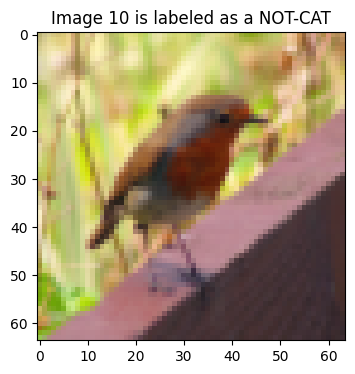

In [ ]:
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# DISCUSSION #3:  Display one of the Training Examples photos at random
# -----------------------------------------------------------------------------------------------------------------
# We pick a random number between 0 and 208, and display that photo from the Training Examples.
# Note that each pixel is displayed as a tiny square of constant color, so all the pixels fit together without
# gaps.  At the enlarged scale of this photo, if you look closely you can see the individual squares.
# Note that the y_train labels are simply 0 or 1, which means either NOT-CAT or CAT, respectively.
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# PLOT ONE TRAINING EXAMPLE
iExample = random.randrange(0, n_train_examples)
exampleName = class_names[y_train[iExample]]
img = np.array(X_train[iExample, :, :])
img = np.reshape(img,(xy_pixels,xy_pixels,n_color_layers))
print('img.shape', img.shape)
plt.figure(figsize=(4, 4))
plt.imshow(img,cmap='gray',vmin=0,vmax=255)
plt.grid(False)
print(y_train[iExample])
plt.title('Image ' + str(iExample) + ' is labeled as a ' + class_names[y_train[iExample]])
plt.show()

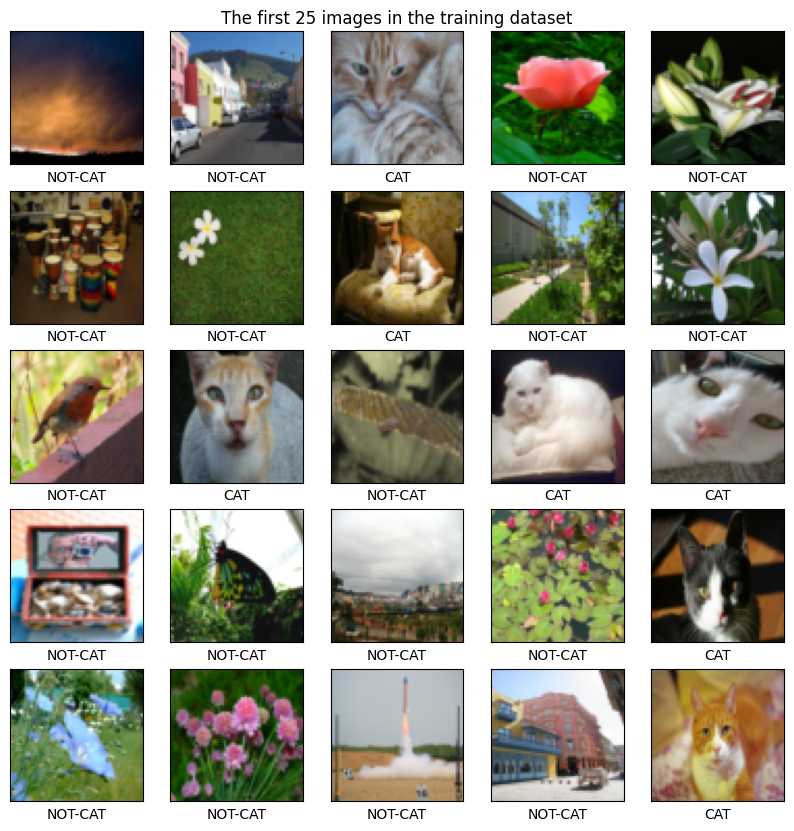

In [ ]:
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# DISCUSSION #4:  Display the first 25 photos in the Training Examples dataset
# -----------------------------------------------------------------------------------------------------------------
# Here are the first 25 photos in the Training Examples file, along with their labels (ground truth values).
# Note that the y_train labels are simply 1 or 0, which means either CAT or NOT-CAT, respectively.
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
#PLOT THE FIRST 25 EXAMPLES
plt.figure(figsize=(10,10))
for i in range(25):
    if(i==3): plt.title('The first 25 images in the training dataset')
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(X_train[i], cmap='gray', vmin=0, vmax=255)
    plt.xlabel(class_names[y_train[i]])
plt.show()

In [ ]:
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# DISCUSSION #5:  Scale the data
# -----------------------------------------------------------------------------------------------------------------
# For images, scaling is really easy because the range of values is already known - 0 to 255.  Therefore to scale
# them to numbers between 0 and 1, just divide the values by 255.
#
# This is a good place to note how easily Python/numpy implements "broadcasting", which means applying an
# operation to an entire matrix.  The statement 'X_train/255' compactly implies dividing every element of the 4-D
# array by 255.  Thus, no nested 'for' loops are needed.
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# SCALE THE DATA
X_train = X_train / 255.0
X_test = X_test / 255.0
print('X_train.shape: ', X_train.shape)
print('X_test.shape: ', X_test.shape)


X_train.shape:  (209, 64, 64, 3)
X_test.shape:  (50, 64, 64, 3)


In [ ]:
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# DISCUSSION #6:  The Model
# -----------------------------------------------------------------------------------------------------------------
# This model is similar to the one used for 'Titanic 1'.  There are 2 relu layers followed by a final sigmoid layer
# to force the "probability of CAT" decision.  The biggest change is the addition of a "Flatten" layer on the
# front-end.
#
# THE FLATTEN LAYER
# Neural networks make decisions (perform forward and backward propagation) based on a 1-D input array* of feature
# values.  As described above, however, a color photo is a 3-D matrix (x dimension, y dimension, 3 layers).
# Therefore, the photo must be reshaped into a big, 1-D array that the network requires for input.  This is
# called "flattening".
#
# For example, here's one layer of a incredibly simple photo that has only 4 pixels!  It is a black & white photo,
# so there is only one "B&W" intensity value at each pixel.  The pixels are numbered 1-4 for convenience in
# tracking how the pixel values are reshaped.
#
#              ------------
#              |  1     2  |
#              |  3     4  |
#              ------------
#
# This photo's 2-D matrix can be 'flattened' by simply reshaping the matrix into a 1-D vector = (  1  2  3  4  ),
# Thus the 2-D matrix of 2 rows x 2 columns would be reshaped into a 1-D vector of the same 4 values.
# If the photo had more than one layer (for example, a color photo would have red, green, and blue layers), each
# layer would be flattened in-turn and added to the 1-D vector.  So for a color photo, the vector would just be
# 3 times longer.
#
# The photos in the CAT dataset are no more complex, they just have more pixels!  Thus, a 64x64x3 photo has
# 3 layers, with each layer containing 64x64 = 4,096 pixel values.  It would be flattened into a 1-D vector that
# has 4,096 x 3 = 12,288 values (= n_values, as computed above).
#
# (Note that Flatten isn't limited to 3 color layers.  Satellite images often have many more layers, one for each
# spectrum that is being captured by its cameras.  Flatten works the same way for them.)
#
# THE DENSE LAYERS
# After the Flatten method, the model's first Dense layer has n_values (12,288) as the number of input nodes -
# which is simply the size of the flattened photo.  From here, the model is tapered (pretty drastically) down
# to 7 nodes in the 2nd layer.  And finally, down to the one sigmoid node in the final layer.
#
# For the Compile instruction, I used a "SGD" (Stochastic Gradient Descent) optimizer simply because it seemed to
# provide better results than an Adam optimizer.
#
# When I ran the model, I needed 700 epochs to get decent results.  (A possible alternative would be to run
# fewer epochs on a more complex model - especially with more nodes in the 2nd layer.  Or maybe add another
# layer.  It's all pretty arbitrary.)
#
#
# *Footnote: Actually X_train is a matrix of Training Examples.  After flattening, it will have a 2nd dimension of
# all the Examples, so it will actually be (209, 12288)
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
#THE MODEL
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(xy_pixels, xy_pixels,n_color_layers)),
    tf.keras.layers.Dense(n_values, activation='relu'),
    tf.keras.layers.Dense(7, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.summary()
model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.0015), loss='binary_crossentropy', metrics=['accuracy'])

#RUN THE MODEL
nEpochs = 700
tf.random.uniform([1], seed=7)  #Specify the weight initialization seed so every run starts with the same weights
history = model.fit(X_train, y_train, epochs=nEpochs, batch_size=n_train_examples, validation_data=(X_test, y_test))




/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 12288)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 12288)               │     151,007,232 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │          86,023 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               8 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 151,093,263 (576.38 MB)

 Trainable params: 151,093,263 (576.38 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/700
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.5933 - loss: 0.6888 - val_accuracy: 0.4200 - val_loss: 0.7413
Epoch 2/700
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.6220 - loss: 0.6779 - val_accuracy: 0.3200 - val_loss: 0.7920
Epoch 3/700
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - accuracy: 0.6507 - loss: 0.6660 - val_accuracy: 0.3200 - val_loss: 0.8202
Epoch 4/700
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.6507 - loss: 0.6601 - val_accuracy: 0.3400 - val_loss: 0.8363
Epoch 5/700
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.6507 - loss: 0.6560 - val_accuracy: 0.3400 - val_loss: 0.8427
Epoch 6/700
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step - accuracy: 0.6507 - loss: 0.6531 - val_accuracy: 0.3400 - val_loss: 0.8502
Epoch 7/700
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.6507 - loss: 0.6507 - val_accuracy: 0.3400 - val_loss: 0.8524
Epoch 8/700
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.6507 - loss: 0.6485 - val_accuracy: 0.3400 - val_los


            ACCURACY         COST
TRAINING  =   99%            0.20
TEST      =   70%            0.63



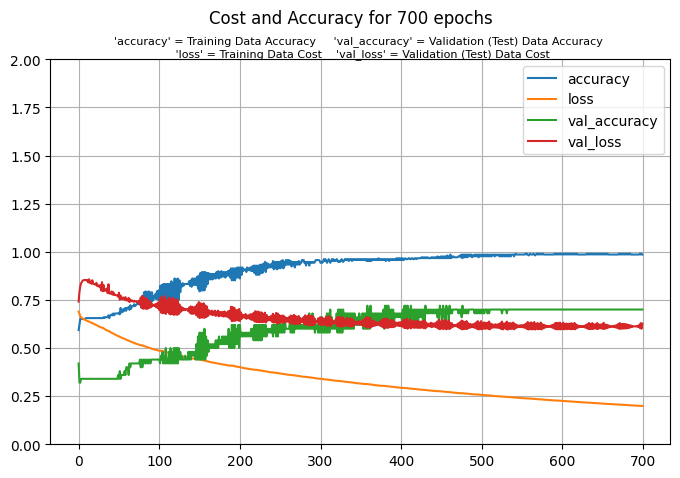

In [ ]:
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# DISCUSSION #7:  Plot statistics
# -----------------------------------------------------------------------------------------------------------------
# These are the standard statistics of cost and accuracy for the Training and Test data.
#
# The Test accuracy and cost for this model look pretty awful!  This is probably not a model one would want to use
# in a production environment.  The accuracy might be improved by running more epochs, using a more complex model,
# or acquiring more training data.  However, bear in mind that the limited resolution of the training photos will
# limit the best accuracy achievable.  Also, part of the determination of whether a model is really useful can be
# determined by reviewing the Heat Map, as described below.
#
# Note that if this program is re-run, the statistics and plot will likely look slightly different (though equally
# bad).  This is because there are a lot of hidden values that are randomly preset, and these make a difference
# in processing the images.
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# PRINT STATISTICS
train_cost,train_accuracy = model.evaluate(X_train, y_train, batch_size=16, verbose=0)
test_cost,test_accuracy = model.evaluate(X_test, y_test, batch_size=16, verbose=0)
print()
print("            ACCURACY         COST")
print("TRAINING  =   {:.0f}%".format(train_accuracy*100), "           {:.2f}".format(train_cost))
print("TEST      =   {:.0f}%".format(test_accuracy*100), "           {:.2f}".format(test_cost))
print()




# PLOT COST AND ACCURACY
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0,2)
plt.suptitle("Cost and Accuracy for " + str(nEpochs) + " epochs")
plt.title(label="'accuracy' = Training Data Accuracy     'val_accuracy' = Validation (Test) Data Accuracy \n 'loss' = "
                "Training Data Cost    'val_loss' = Validation (Test) Data Cost", pad=0, fontsize=8)
plt.show()


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 465ms/step
cat_probabilities.shape: (50, 1)
cat_predictions.shape: (50, 1)
y_test.shape: (50,)


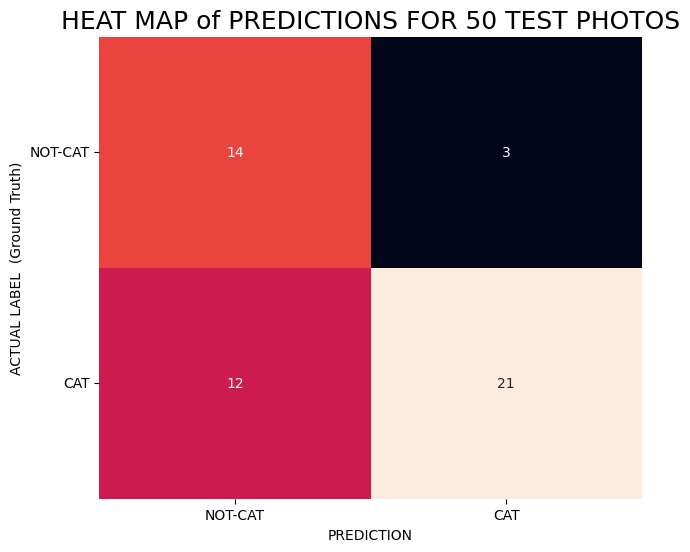

In [ ]:
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# DISCUSSION #8:  Plot a "Heat Map" Confusion Matrix on the Test Examples
# -----------------------------------------------------------------------------------------------------------------
# A Confusion Matrix shows all the Testing Examples' outcomes collected into a square of 4 groupings for quick
# comparison.  The Confusion Matrix is run on the Test Examples (rather than the Training Examples) because those
# are the best indicators of how accurate the model will be on new Examples.
#
#
# Another way to present a Confusion Matrix is as a Heat Map.  This more visual representation shows the 4
# Confusion Matrix values within squares which are colored to match their values.  Higher, better values are
# lighter in color.
#
# It can be read by noting that the 2 possible predictions are displayed along the horizontal x-axis.  And the
# given labels (ground truth) are displayed along the vertical y-axis.  So, for example:
#  - The box in the lower-right corner is at the intersection of a CAT Prediction (x-axis) with a CAT Label ground
#      truth (y-axis).  Therefore, the number in the box shows how many correct CAT predictions were made.
#  - Similarly, the upper-left box shows how many correct NOT-CAT predictions there were.
#  - The upper-right box shows how many CAT predictions were incorrect, and
#  - The lower-left box shows how many NON-CAT predictions were incorrect.
#
# Ideally, the "true" diagonal of correctly predicted CATs and NOT-CATs - upper left to lower right - should be
# far greater (and therefore far brighter in color) than the "false" diagonal of incorrectly predicted outcomes
# - lower left to upper right.
#
# For this model, the "true" diagonal is fairly bright, which is good.
# It looks like the main source for errors is that the model incorrectly classifies many CATs as NOT-CATs
# (lower-left box).  It rarely mis-classified NOT-CATs as CATs (upper-right box), at about 10% of the time.  If
# this type of error is acceptable - for example, if the primary objective is that all NON-CATs be identified -
# then the fact that the model mis-classifies some extra CATs as NON-CATs could be overlooked.  It all depends
# on the goal of the modeling.
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
#PLOT HEAT MAP OF CONFUSION MATRIX
n_test_examples = y_test.shape[0]
# Predict the values from the test dataset.  cat_probabilities is 2D array (rows=#examples,cols=features=1)
cat_probabilities = model.predict(X_test)
print('cat_probabilities.shape:', cat_probabilities.shape)
min_for_cat = 0.5
cat_predictions = cat_probabilities >= min_for_cat
print('cat_predictions.shape:', cat_predictions.shape)
print('y_test.shape:', y_test.shape)
confusion_mtx = tf.math.confusion_matrix(y_test, cat_predictions)   # compute the confusion matrix
plt.figure(figsize=(7,6))
c = sns.heatmap(confusion_mtx, annot=True, cbar=False, fmt='g')
c.set(xticklabels=class_names, yticklabels=class_names)
c.set_yticklabels(c.get_yticklabels(), rotation=0)
plt.xlabel("PREDICTION")
plt.ylabel("ACTUAL LABEL  (Ground Truth)")
plt.title('HEAT MAP of PREDICTIONS FOR ' + str(n_test_examples) + ' TEST PHOTOS', fontdict={'fontsize':18})
plt.show()




In [ ]:
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
# DISCUSSION #9:  Store the Model for use in a later program
# -----------------------------------------------------------------------------------------------------------------
# This program takes a long time to run.  Consequently, it is useful to store the resulting model and its weights
# so it doesn't have to be rerun every time new data needs to be evaluated.
#
# The 'save' method stores the model as a file, whose descriptive name we can choose.
#
# Later, to use the stored model, the file name is input to a subsequent program, such as 'Cat_notCat_Use.py',
# which will use the weights in the file to reconstitute the evaluation model.
# :::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::
print()
print("Writing the Model; please wait...")
filename_for_model = '/content/catnotcat_weights.keras'
model.save(filename_for_model)
print('Model saved in folder = ', filename_for_model)



Writing the Model; please wait...
Model saved in folder =  /content/catnotcat_weights.keras
